# 🎤 Mini Project: Which K-pop Song Is the Most Popular?

**Research question:** Which K-pop song has the most YouTube views, and which song of each group has the most views?

**What this project does:**
1. Downloads 3 tables from Kaggle.
2. Loads them with Pandas, filters them and joins them together.
3. Answers questions using sorting, grouping (`groupby`) and charts.
4. Builds a simple question menu: the user types a group name or a year and gets an answer.

**The tables:**

| # | Table | What's inside | Source |
|---|---|---|---|
| 1 | Spotify and YouTube | YouTube views, Spotify streams, likes, album | [Kaggle](https://www.kaggle.com/datasets/salvatorerastelli/spotify-and-youtube) |
| 2 | 400+ K-Pop Groups | Record label, debut date, number of members | [Kaggle](https://www.kaggle.com/datasets/nicolsalayoarias/kpop-groups-dataset) |
| 3 | Kpop song rankings | Official weekly Korean chart (Circle Chart), 2010–2023 | [Kaggle](https://www.kaggle.com/datasets/romainfonta2/kpop-song-rankings) |

## Step 1: Download the data from Kaggle

The `kagglehub` library downloads a dataset from Kaggle and returns the folder it was saved to. Public datasets don't require a login.

In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt

# Show big numbers with commas (2,012,854,627) instead of 2.01e+09
pd.options.display.float_format = "{:,.0f}".format

path_spotify_youtube = kagglehub.dataset_download("salvatorerastelli/spotify-and-youtube")
path_groups = kagglehub.dataset_download("nicolsalayoarias/kpop-groups-dataset")
path_rankings = kagglehub.dataset_download("romainfonta2/kpop-song-rankings")

print("Data downloaded successfully ✅")

Data downloaded successfully ✅


## Step 2: Load the main table

`pd.read_csv` reads a CSV file and turns it into a table (a DataFrame).

In [2]:
songs = pd.read_csv(path_spotify_youtube + "/Spotify_Youtube.csv")

print("Rows and columns:", songs.shape)
songs.head()

Rows and columns: (20718, 28)


,Unnamed: 0,Artist,Url_spotify,Track,Album,Album_type,Uri,Danceability,Energy,Key,...,Url_youtube,Title,Channel,Views,Likes,Comments,Description,Licensed,official_video,Stream
0,0,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,Feel Good Inc.,Demon Days,album,spotify:track:0d28khcov6AiegSCpG5TuT,1,1,6,...,https://www.youtube.com/watch?v=HyHNuVaZJ-k,Gorillaz - Feel Good Inc. (Official Video),Gorillaz,"693,555,221","6,220,896","169,907",Official HD Video for Gorillaz' fantastic trac...,True,True,"1,040,234,854"
1,1,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,Rhinestone Eyes,Plastic Beach,album,spotify:track:1foMv2HQwfQ2vntFf9HFeG,1,1,8,...,https://www.youtube.com/watch?v=yYDmaexVHic,Gorillaz - Rhinestone Eyes [Storyboard Film] (...,Gorillaz,"72,011,645","1,079,128","31,003",The official video for Gorillaz - Rhinestone E...,True,True,"310,083,733"
2,2,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,New Gold (feat. Tame Impala and Bootie Brown),New Gold (feat. Tame Impala and Bootie Brown),single,spotify:track:64dLd6rVqDLtkXFYrEUHIU,1,1,1,...,https://www.youtube.com/watch?v=qJa-VFwPpYA,Gorillaz - New Gold ft. Tame Impala & Bootie B...,Gorillaz,"8,435,055","282,142","7,399",Gorillaz - New Gold ft. Tame Impala & Bootie B...,True,True,"63,063,467"
3,3,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,On Melancholy Hill,Plastic Beach,album,spotify:track:0q6LuUqGLUiCPP1cbdwFs3,1,1,2,...,https://www.youtube.com/watch?v=04mfKJWDSzI,Gorillaz - On Melancholy Hill (Official Video),Gorillaz,"211,754,952","1,788,577","55,229",Follow Gorillaz online:\nhttp://gorillaz.com \...,True,True,"434,663,559"
4,4,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,Clint Eastwood,Gorillaz,album,spotify:track:7yMiX7n9SBvadzox8T5jzT,1,1,10,...,https://www.youtube.com/watch?v=1V_xRb0x9aw,Gorillaz - Clint Eastwood (Official Video),Gorillaz,"618,480,958","6,197,318","155,930",The official music video for Gorillaz - Clint ...,True,True,"617,259,738"


The table has more than 20,000 songs from all over the world. We keep only the columns we need:

| Column | Meaning |
|---|---|
| `Artist` | Artist / group |
| `Track` | Song title |
| `Album` | Album name |
| `Views` | YouTube views |
| `Likes` | YouTube likes |
| `Stream` | Spotify streams |

In [3]:
songs = songs[["Artist", "Track", "Album", "Views", "Likes", "Stream"]]
songs.head()

,Artist,Track,Album,Views,Likes,Stream
0,Gorillaz,Feel Good Inc.,Demon Days,"693,555,221","6,220,896","1,040,234,854"
1,Gorillaz,Rhinestone Eyes,Plastic Beach,"72,011,645","1,079,128","310,083,733"
2,Gorillaz,New Gold (feat. Tame Impala and Bootie Brown),New Gold (feat. Tame Impala and Bootie Brown),"8,435,055","282,142","63,063,467"
3,Gorillaz,On Melancholy Hill,Plastic Beach,"211,754,952","1,788,577","434,663,559"
4,Gorillaz,Clint Eastwood,Gorillaz,"618,480,958","6,197,318","617,259,738"


## Step 3: Filter – K-pop songs only

We make a list of groups and artists, and use `isin` to keep only the rows whose artist is in that list.

In [4]:
kpop_artists = [
    "BTS", "BLACKPINK", "TWICE", "Stray Kids", "SEVENTEEN", "EXO",
    "NewJeans", "ITZY", "IVE", "(G)I-DLE", "Red Velvet", "ATEEZ",
    "TOMORROW X TOGETHER", "ENHYPEN", "NCT 127", "NCT DREAM", "BIGBANG",
    "LE SSERAFIM", "Girls' Generation", "PSY", "IU", "Jung Kook", "Jimin"
]

kpop = songs[songs["Artist"].isin(kpop_artists)]

print("K-pop songs in the table:", len(kpop))
print("Number of artists:", kpop["Artist"].nunique())

K-pop songs in the table: 216
Number of artists: 23


### Data cleaning

We check for missing values (`isna`). A song without a view count doesn't help us, so we remove it with `dropna`.

In [5]:
print("Missing values per column:")
print(kpop.isna().sum())

kpop = kpop.dropna(subset=["Views"])
print()
print("After cleaning,", len(kpop), "songs are left")

Missing values per column:
Artist     0
Track      0
Album      0
Views      1
Likes      2
Stream    16
dtype: int64

After cleaning, 215 songs are left


## Step 4: First question – the 10 most viewed songs on YouTube

`sort_values` sorts the table by a column. `ascending=False` means from largest to smallest.

In [6]:
top10 = kpop.sort_values("Views", ascending=False).head(10)
top10[["Artist", "Track", "Views"]]

,Artist,Track,Views
8937,PSY,Gangnam Style (강남스타일),"4,679,767,471"
18004,BLACKPINK,DDU-DU DDU-DU,"2,012,854,627"
18001,BLACKPINK,Kill This Love,"1,734,794,444"
14561,BTS,Dynamite,"1,640,945,859"
14565,BTS,Boy With Luv (feat. Halsey),"1,634,109,865"
8939,PSY,Gentleman,"1,539,136,154"
18000,BLACKPINK,BOOMBAYAH,"1,532,197,552"
17998,BLACKPINK,As If It's Your Last,"1,246,371,120"
17999,BLACKPINK,How You Like That,"1,182,611,467"
14566,BTS,Butter,"850,329,651"


### Chart

Billions are hard to read, so we divide by 1,000,000 and show the views in millions.

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44053 (\N{HANGUL SYLLABLE GANG}) missing from font(s) DejaVu Sans, Inter, DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 45224 (\N{HANGUL SYLLABLE NAM}) missing from font(s) DejaVu Sans, Inter, DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans, Inter, DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 53440 (\N{HANGUL SYLLABLE TA}) missing from font(s) DejaVu Sans, Inter, DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) mi

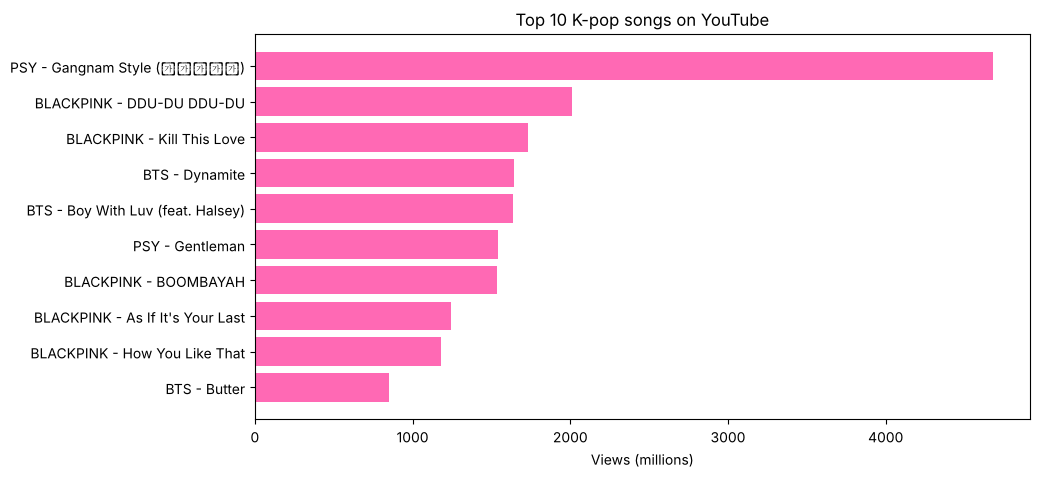

In [7]:
labels = top10["Artist"] + " - " + top10["Track"]

plt.figure(figsize=(10, 5))
plt.barh(labels, top10["Views"] / 1_000_000, color="hotpink")
plt.gca().invert_yaxis()
plt.xlabel("Views (millions)")
plt.title("Top 10 K-pop songs on YouTube")
plt.show()

## Step 5: The most viewed song of each group

`groupby("Artist")` splits the table into groups by artist. `idxmax()` finds, in each group, the row with the most views.

In [8]:
best_rows = kpop.groupby("Artist")["Views"].idxmax()
best_song_per_artist = kpop.loc[best_rows].sort_values("Views", ascending=False)

best_song_per_artist[["Artist", "Track", "Views"]]

,Artist,Track,Views
8937,PSY,Gangnam Style (강남스타일),"4,679,767,471"
18004,BLACKPINK,DDU-DU DDU-DU,"2,012,854,627"
14561,BTS,Dynamite,"1,640,945,859"
8071,TWICE,What is Love,"697,538,531"
12979,BIGBANG,BANG BANG BANG,"623,574,619"
17115,EXO,Love Shot,"553,619,697"
19806,(G)I-DLE,POP/STARS,"541,864,471"
20185,ITZY,WANNABE,"486,276,423"
19158,Stray Kids,God’s Menu,"377,725,410"
17527,Red Velvet,Bad Boy,"377,692,019"


## Step 6: Which group has the most views overall?

This time we add up (`sum`) all the views of each group.

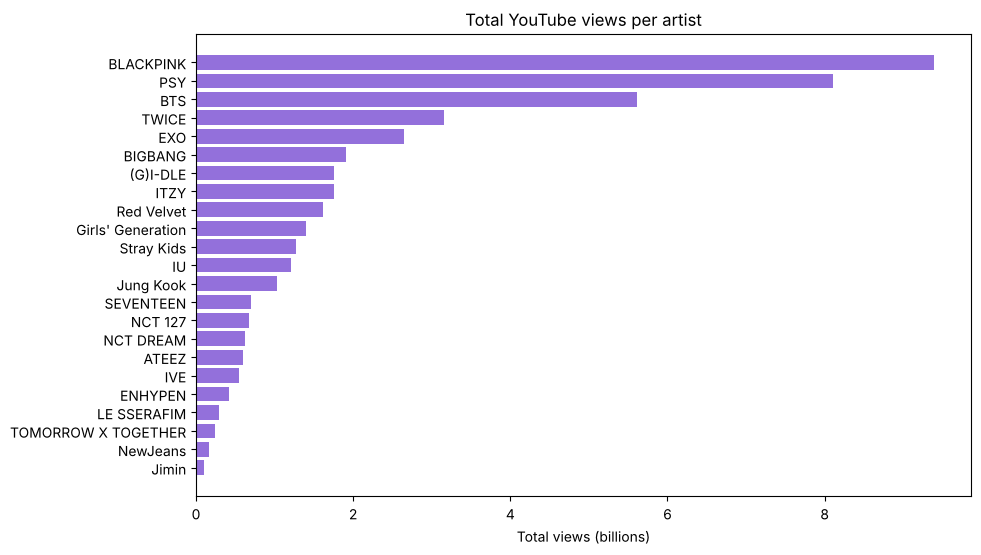

In [9]:
total_views = kpop.groupby("Artist")["Views"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(total_views.index, total_views / 1_000_000_000, color="mediumpurple")
plt.gca().invert_yaxis()
plt.xlabel("Total views (billions)")
plt.title("Total YouTube views per artist")
plt.show()

## Step 7: YouTube vs. Spotify

Is the most viewed song on YouTube also the most streamed song on Spotify?

In [10]:
top_spotify = kpop.sort_values("Stream", ascending=False).head(10)
top_spotify[["Artist", "Track", "Stream"]]

,Artist,Track,Stream
14561,BTS,Dynamite,"1,582,446,481"
14566,BTS,Butter,"1,066,001,876"
14565,BTS,Boy With Luv (feat. Halsey),"989,478,029"
14562,BTS,My Universe,"883,224,238"
17999,BLACKPINK,How You Like That,"733,213,843"
18001,BLACKPINK,Kill This Love,"661,790,347"
18004,BLACKPINK,DDU-DU DDU-DU,"565,754,284"
14567,BTS,Permission to Dance,"560,895,612"
14560,BTS,Left and Right (Feat. Jung Kook of BTS),"487,102,924"
17998,BLACKPINK,As If It's Your Last,"435,656,437"


## Step 8: Joining the second table – record labels

The second table has information about the groups themselves. We join it to our table with `merge`.
The shared column is the group name: in our table it's called `Artist`, and in the second table it's `Name`.

In [11]:
groups = pd.read_csv(path_groups + "/kpopgroups.csv")
groups = groups[["Name", "Company", "Debut", "Gender", "Members"]]
groups.head()

,Name,Company,Debut,Gender,Members
0,(G)I-DLE,Cube,2/05/2018,Female,5
1,100%,TOP Media,18/09/2012,Male,4
2,14U,BG,17/04/2017,Male,14
3,15&,JYP,5/10/2012,Female,2
4,1TEAM,LiveWorks,27/03/2019,Male,5


In [12]:
kpop_with_info = kpop.merge(groups, left_on="Artist", right_on="Name", how="left")
kpop_with_info = kpop_with_info.drop(columns="Name")

kpop_with_info[["Artist", "Track", "Views", "Company", "Gender"]].head(10)

,Artist,Track,Views,Company,Gender
0,TWICE,MOONLIGHT SUNRISE,"50,381,801",JYP,Female
1,TWICE,Talk that Talk,"132,108,378",JYP,Female
2,TWICE,The Feels,"346,384,506",JYP,Female
3,TWICE,FANCY,"565,262,008",JYP,Female
4,TWICE,What is Love,"697,538,531",JYP,Female
5,TWICE,I CAN'T STOP ME,"477,671,640",JYP,Female
6,TWICE,CRY FOR ME,"25,161,087",JYP,Female
7,TWICE,Feel Special,"459,290,870",JYP,Female
8,TWICE,Alcohol-Free,"261,953,361",JYP,Female
9,TWICE,SCIENTIST,"138,040,342",JYP,Female


> 💡 Solo artists (like PSY or IU) aren't in the groups table, so they get `NaN` (a missing value). That's fine.

### Which record label gets the most views?

In [13]:
by_company = kpop_with_info.groupby("Company")["Views"].sum().sort_values(ascending=False)
by_company

Company
YG         11,306,995,622
JYP         6,174,911,563
SM          5,669,734,399
Big Hit     5,607,867,002
Cube        1,754,953,941
KQ            597,259,504
Starship      545,146,949
Be:lift       422,723,629
Source        288,420,439
ADOR          158,863,468
Name: Views, dtype: float64

### Boy groups vs. girl groups

In [14]:
kpop_with_info.groupby("Gender")["Views"].mean().sort_values(ascending=False)

Gender
Female   233,370,279
Male     207,617,208
Name: Views, dtype: float64

## Step 9: The third table – the most popular song of each year

In this table, each row is a song at a certain position in the chart of a certain week.
To find the most popular song of a year, we count **how many weeks each song was at number 1**.

In [15]:
rankings = pd.read_csv(path_rankings + "/kpop_rankings.csv")
rankings.head()

,year,time,rank,song_title,artist,album
0,2010,1,1,우리 사랑하게 됐어요.,"가인, 조권",우리 사랑하게 됐어요
1,2010,1,2,처음처럼 그때처럼 (Feat. 강민경),이승기,Shadow (Repackage)
2,2010,1,3,그대라서,거미,크리스마스에 눈이 올까요? OST
3,2010,1,4,Bo Peep Bo Peep,티아라 (T-ara),Absolute First Album
4,2010,1,5,술 한잔 해요,지아 (Zia),Atelier


In [16]:
number_one = rankings[rankings["rank"] == 1]

weeks_at_top = (
    number_one.groupby(["year", "song_title", "artist"])
    .size()
    .reset_index(name="weeks_at_1")
    .sort_values(["year", "weeks_at_1"], ascending=[True, False])
)

weeks_at_top.groupby("year").head(1)

,year,song_title,artist,weeks_at_1
1,2010,Bad Girl Good Girl,miss A,4
54,2011,나만 몰랐던 이야기,아이유 (IU),3
71,2012,Lovey-Dovey,티아라 (T-ara),1
72,2013,I Got A Boy,소녀시대,1
73,2014,그대가 분다,엠씨더맥스 (M.C The Max),1
85,2015,같은 시간 속의 너,나얼,4
125,2016,TT,TWICE,4
158,2017,Ko Ko Bop,EXO,4
194,2018,겨울소리,박효신,1
195,2019,180도,벤 (Ben),1


> ⚠️ Note: for some years (2012–2014, 2018–2019) the table has only one or two weeks of charts, so the result for those years is less reliable. That's a finding too – before trusting an answer, check how much data is behind it.

In [17]:
# How many chart weeks are there for each year?
rankings.groupby("year")["time"].nunique()

year
2010    52
2011    52
2012     1
2013     1
2014     1
2015    53
2016    52
2017    52
2018     1
2019     1
2020    52
2021    52
2022    52
2023    44
Name: time, dtype: int64

## Step 10: The interface – ask a question, get an answer

We build functions that each answer one type of question, and then a menu that runs them.

In the Korean chart some artist names are written in Korean, so a small dictionary translates them.

In [18]:
korean_names = {
    "BTS": "방탄소년단",
    "SEVENTEEN": "세븐틴",
    "Girls' Generation": "소녀시대",
    "(G)I-DLE": "(여자)아이들",
    "PSY": "싸이",
    "Jung Kook": "정국",
    "Red Velvet": "레드벨벳",
}


def find_artist(name):
    """Return the exact name from the table, ignoring upper/lower case."""
    for artist in kpop["Artist"].unique():
        if artist.lower() == name.strip().lower():
            return artist
    return None


def most_viewed_song(name):
    """Which song of this group got the most YouTube views?"""
    artist = find_artist(name)
    if artist is None:
        print("❌ Couldn't find", name, "– try one of these:")
        print(", ".join(sorted(kpop["Artist"].unique())))
        return
    artist_songs = kpop[kpop["Artist"] == artist].sort_values("Views", ascending=False)
    best = artist_songs.iloc[0]
    print(f"🏆 Most viewed song by {artist}: {best['Track']}")
    print(f"   {best['Views']:,.0f} YouTube views")
    print()
    print("Top 5 songs:")
    print(artist_songs[["Track", "Views"]].head(5).to_string(index=False))


def most_popular_in_year(year):
    """What was the most popular song on the Korean chart in a given year?"""
    result = weeks_at_top[weeks_at_top["year"] == year]
    if result.empty:
        print("❌ No data for", year, "– data is available for 2010 to 2023")
        return
    best = result.iloc[0]
    print(f"🏆 Most popular song of {year}: {best['song_title']} – {best['artist']}")
    print(f"   {best['weeks_at_1']} weeks at number 1")


def compare_artists(name1, name2):
    """Who has more views in total?"""
    a1, a2 = find_artist(name1), find_artist(name2)
    if a1 is None or a2 is None:
        print("❌ One of the names wasn't found")
        return
    v1 = kpop[kpop["Artist"] == a1]["Views"].sum()
    v2 = kpop[kpop["Artist"] == a2]["Views"].sum()
    winner = a1 if v1 > v2 else a2
    print(f"{a1}: {v1:,.0f} views")
    print(f"{a2}: {v2:,.0f} views")
    print(f"🏆 Winner: {winner}")


def artist_chart_history(name):
    """How many weeks was this group at number 1 on the Korean chart?"""
    artist = find_artist(name) or name.strip()
    search = korean_names.get(artist, artist)
    rows = number_one[number_one["artist"].str.contains(search, case=False, regex=False)]
    if rows.empty:
        print(f"{artist} has no weeks at number 1 in our data")
        return
    print(f"⭐ {artist} was at number 1 for {len(rows)} weeks. Songs:")
    print(rows.groupby("song_title").size().sort_values(ascending=False).to_string())

### Testing the functions

In [19]:
most_viewed_song("blackpink")

🏆 Most viewed song by BLACKPINK: DDU-DU DDU-DU
   2,012,854,627 YouTube views

Top 5 songs:
               Track         Views
       DDU-DU DDU-DU 2,012,854,627
      Kill This Love 1,734,794,444
           BOOMBAYAH 1,532,197,552
As If It's Your Last 1,246,371,120
   How You Like That 1,182,611,467


In [20]:
most_popular_in_year(2020)

🏆 Most popular song of 2020: Dynamite – 방탄소년단
   11 weeks at number 1


In [21]:
compare_artists("BTS", "BLACKPINK")

BTS: 5,607,867,002 views
BLACKPINK: 9,392,961,989 views
🏆 Winner: BLACKPINK


In [22]:
artist_chart_history("BTS")

⭐ BTS was at number 1 for 19 weeks. Songs:
song_title
Dynamite    11
Butter       5
ON           1
봄날           1
피 땀 눈물       1


### The menu

Run the cell, choose a number and type what the program asks for. Choose 0 to exit.

In [ ]:
def menu():
    while True:
        print()
        print("===== 🎤 K-pop Quiz =====")
        print("1 - Which song of a group got the most views?")
        print("2 - What was the most popular song in a given year?")
        print("3 - Compare two groups")
        print("4 - How many weeks was a group at number 1?")
        print("5 - The 10 most viewed songs")
        print("0 - Exit")
        choice = input("Choose a number: ").strip()

        if choice == "1":
            most_viewed_song(input("Group name: "))
        elif choice == "2":
            year = input("Year (2010-2023): ").strip()
            if year.isdigit():
                most_popular_in_year(int(year))
            else:
                print("❌ Please type the year as a number")
        elif choice == "3":
            compare_artists(input("First group: "), input("Second group: "))
        elif choice == "4":
            artist_chart_history(input("Group name: "))
        elif choice == "5":
            print(top10[["Artist", "Track", "Views"]].to_string(index=False))
        elif choice == "0":
            print("Bye! 👋")
            break
        else:
            print("❌ That option doesn't exist")


menu()

## Summary and conclusions

Write your conclusions here. Some questions that can help:
- Which K-pop song is the most viewed on YouTube? Did it surprise you?
- Is the most viewed song on YouTube also the most streamed on Spotify?
- Which record label is the most successful on YouTube?
- Is there a difference between boy groups and girl groups?

## Data limitations

- The views in the main table were collected in early 2023. The numbers have grown since then, and songs released after 2023 aren't included.
- Each artist has only about 10 songs in the table, not their full discography.
- The Korean chart goes up to 2023, and many weeks are missing in some years.
- Some artist names in the third table are written in Korean.

To check 2026 views, you'd need a more recent dataset, or to collect the data directly from YouTube.